# 02 — Baseline XGBoost + MLflow

Keputusan dari EDA yang diterapkan di sini:

| Keputusan | Penerapan |
|---|---|
| Hanya TRANSFER & CASH_OUT | Tipe lain tidak pernah fraud di PaySim → langsung ALLOW |
| Pemotongan opsi A | Step ≤400, 70/15/15 berurutan waktu; step >400 = uji drift |
| Buang `newbalance*` | Saldo setelah transaksi = kebocoran |
| `hour` | Default **tanpa** `hour`; versi dengan `hour` sebagai pembanding |
| Kuras saldo | Masuk model default; versi tanpa kuras sebagai pembanding |

**Aturan main:** model dibandingkan di **validasi**. Test dibuka **sekali saja** di akhir, untuk model yang sudah dipilih.

In [1]:
import sys, pathlib, time
ROOT = pathlib.Path('..').resolve()
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow, mlflow.xgboost
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

from fraud.features import build_features, temporal_split, BASE_FEATURES
from fraud.decision import total_cost, FALSE_POSITIVE_COST

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")
mlflow.set_experiment('paysim-baseline')

2026/11/10 19:49:04 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 19:49:04 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 19:49:05 INFO mlflow.tracking.fluent: Experiment with name 'paysim-baseline' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:///d:/MATERIKULIAH/OWNPROJECT/FRAUDDETECTION/fraud-detection/notebooks/mlruns/1', creation_time=1794311345994, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794311345994, lifecycle_stage='active', name='paysim-baseline', tags={}, trace_location=None, workspace='default'>

## 1. Fitur
`build_features` (di `src/fraud/features.py`) hanya memakai informasi yang ada **sebelum** transaksi disetujui. Dua fitur riwayat menghitung transaksi yang datang lebih dulu:
- `recv_count_24h`, `recv_sum_24h`: berapa kali (dan berapa total) akun penerima menerima uang dalam 24 jam terakhir. Ini fitur akun penampung.
- `same_amount_2h`: berapa transaksi sebelumnya bernominal persis sama dalam 2 jam terakhir. Ini menangkap pola TRANSFER → CASH_OUT.

In [2]:
df = pd.read_parquet(ROOT / 'data/processed/paysim.parquet')
t0 = time.time()
feat = build_features(df)
print(f"{len(feat):,} baris TRANSFER+CASH_OUT, dibuat dalam {time.time() - t0:.0f} detik")
feat.groupby('isFraud')[['recv_count_24h', 'same_amount_2h', 'kuras', 'dest_zero_before']].mean()

2,770,409 baris TRANSFER+CASH_OUT, dibuat dalam 7 detik


,recv_count_24h,same_amount_2h,kuras,dest_zero_before
isFraud,,,,
0,1.6399,0.9071,0.0000,0.1390
1,0.3270,1.1903,0.9782,0.6515


## 2. Pemotongan data (opsi A)

In [3]:
train, val, test, drift, (cut1, cut2) = temporal_split(feat, max_step=400)
print(f"Batas: train ≤ step {cut1}, validasi ≤ step {cut2}, test ≤ step 400, drift > 400\n")
pd.DataFrame({
    name: {'baris': len(d), 'fraud': int(d.isFraud.sum()), 'tingkat_fraud': d.isFraud.mean()}
    for name, d in [('train', train), ('validasi', val), ('test', test), ('drift', drift)]
}).T

Batas: train ≤ step 300, validasi ≤ step 350, test ≤ step 400, drift > 400



,baris,fraud,tingkat_fraud
train,"1,780,544.0000","3,401.0000",0.0019
validasi,"380,409.0000",500.0000,0.0013
test,"368,583.0000",576.0000,0.0016
drift,"240,873.0000","3,736.0000",0.0155


> **💡 Perhatikan:** bandingkan tingkat fraud train, validasi, dan test dengan set drift. Inilah alasan kita memilih opsi A.

## 3. Patokan sebelum model
Model baru berguna kalau lebih murah daripada cara yang tidak memakai model. Biaya dihitung dengan aturan yang sudah kita sepakati: fraud lolos = nominal, salah blokir = Rp 200 ribu.

In [4]:
baselines = {
    'tanpa blokir': total_cost(val.isFraud, val.amount, np.zeros(len(val), bool)),
    'aturan kuras saldo': total_cost(val.isFraud, val.amount, val.kuras == 1),
}
pd.DataFrame(baselines).T

,biaya_total,fraud_lolos_rp,salah_blokir,fraud_tertangkap,fraud_total
tanpa blokir,"675,101,731.1400","675,101,731.1400",0.0000,0.0000,500.0000
aturan kuras saldo,"50,000,000.0000","50,000,000.0000",0.0000,495.0000,500.0000


## 4. Eksperimen
Satu fungsi untuk semua eksperimen, supaya perbandingannya adil (data, parameter, dan cara menilai sama).

**Kenapa tidak memakai `scale_pos_weight`?** Pengaturan itu sering dipakai untuk data tidak seimbang, tetapi membuat skor model tidak lagi berarti "peluang fraud". Aturan BLOCK kita (`skor × nominal > (1 − skor) × 200 ribu`) membutuhkan skor yang benar-benar peluang. Baris `kalibrasi` di hasil mengecek hal ini: rata-rata skor seharusnya dekat dengan tingkat fraud asli.

**Kenapa early stopping memakai `logloss`, bukan `aucpr`?** XGBoost berhenti berdasarkan metrik **terakhir** di `eval_metric`. Di PaySim, AUC sudah hampir 1 sejak pohon pertama (karena kuras saldo), jadi `aucpr` tidak bisa naik lagi dan pelatihan berhenti terlalu dini. Skornya masih kecil semua, sehingga aturan biaya jarang memblokir. `logloss` terus membaik selama skor makin mendekati peluang yang sebenarnya, dan hal itulah yang dibutuhkan aturan BLOCK.

In [5]:
PARAMS = dict(n_estimators=1000, learning_rate=0.05, max_depth=6, subsample=0.8,
              colsample_bytree=0.8, tree_method='hist', eval_metric=['aucpr', 'logloss'],
              early_stopping_rounds=50, n_jobs=-1, random_state=42)

def run_experiment(name, features):
    with mlflow.start_run(run_name=name):
        model = XGBClassifier(**PARAMS)
        model.fit(train[features], train.isFraud,
                  eval_set=[(val[features], val.isFraud)], verbose=False)
        score = model.predict_proba(val[features])[:, 1]
        blocked = score * val.amount.to_numpy() > (1 - score) * FALSE_POSITIVE_COST
        cost = total_cost(val.isFraud, val.amount, blocked)
        metrics = {
            'roc_auc': roc_auc_score(val.isFraud, score),
            'pr_auc': average_precision_score(val.isFraud, score),
            'kalibrasi_skor_rata2': float(score.mean()),
            'kalibrasi_fraud_asli': float(val.isFraud.mean()),
            'pohon_terpakai': model.best_iteration + 1,
            **cost,
        }
        mlflow.log_params({**PARAMS, 'features': ','.join(features), 'cut1': cut1, 'cut2': cut2})
        mlflow.log_metrics(metrics)
        mlflow.xgboost.log_model(model, name='model')
    return model, metrics

FEATURE_SETS = {
    'default (tanpa hour)': BASE_FEATURES + ['kuras'],
    '+ hour':               BASE_FEATURES + ['kuras', 'hour'],
    'tanpa kuras':          BASE_FEATURES,
}
models, results = {}, {}
for name, cols in FEATURE_SETS.items():
    models[name], results[name] = run_experiment(name, cols)
    print(f"selesai: {name}")

hasil = pd.DataFrame(results).T
hasil[['roc_auc', 'pr_auc', 'biaya_total', 'fraud_tertangkap', 'fraud_total', 'salah_blokir',
       'kalibrasi_skor_rata2', 'kalibrasi_fraud_asli', 'pohon_terpakai']]

selesai: default (tanpa hour)
selesai: + hour
selesai: tanpa kuras


,roc_auc,pr_auc,biaya_total,fraud_tertangkap,fraud_total,salah_blokir,kalibrasi_skor_rata2,kalibrasi_fraud_asli,pohon_terpakai
default (tanpa hour),1.0000,1.0000,"400,000.0000",500.0000,500.0000,2.0000,0.0013,0.0013,990.0000
+ hour,1.0000,1.0000,"600,000.0000",500.0000,500.0000,3.0000,0.0013,0.0013,991.0000
tanpa kuras,1.0000,0.9947,"3,420,405.7500",496.0000,500.0000,17.0000,0.0013,0.0013,229.0000


Semua run juga tercatat di MLflow. Dari folder proyek, jalankan di terminal:
```
mlflow ui --backend-store-uri sqlite:///mlflow.db
```
lalu buka http://127.0.0.1:5000.

## 5. Fitur apa yang dipakai model?

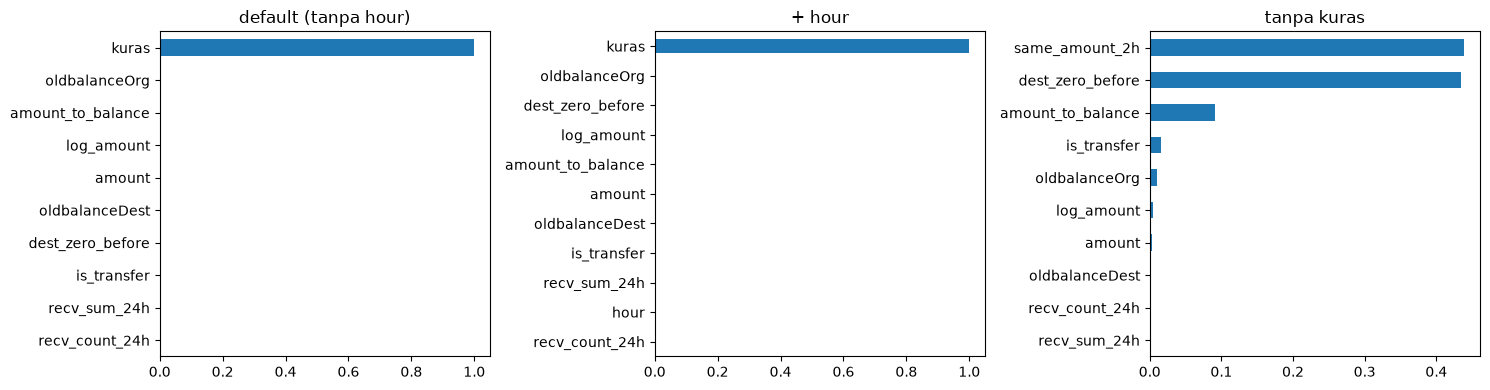

In [6]:
fig, axes = plt.subplots(1, len(models), figsize=(15, 4))
for ax, (name, m) in zip(axes, models.items()):
    imp = pd.Series(m.get_booster().get_score(importance_type='gain')).sort_values()
    (imp / imp.sum()).plot.barh(ax=ax, title=name)
plt.tight_layout(); plt.show()

> **🧠 Bahan diskusi:**
> - Bandingkan `default` dengan `+ hour`. Kalau `hour` menaikkan skor, apakah itu karena model lebih pintar, atau karena artefak "fraud 10 per jam" yang kita temukan di EDA?
> - Bandingkan `default` dengan `tanpa kuras`. Seberapa jauh fitur lain bisa menggantikan kuras saldo? Fitur mana yang naik di grafik?
> - Apakah model mengalahkan patokan **aturan kuras saldo**? Kalau selisihnya kecil, apa artinya untuk PaySim?
>
> _Catatanmu:_
> tanpa kuras membuat fitur lain lebih berpengaruh

## 6. Uji akhir: test dan drift
Jalankan bagian ini **sekali** setelah memilih model. Kalau hasil test dipakai untuk mengubah pilihan model, test itu berubah fungsi jadi validasi kedua, dan kita kehilangan penilaian yang jujur.

In [7]:
CHOSEN = 'default (tanpa hour)'
model, cols = models[CHOSEN], FEATURE_SETS[CHOSEN]

rows = {}
for name, d in [('validasi', val), ('test', test), ('drift (>400)', drift)]:
    s = model.predict_proba(d[cols])[:, 1]
    b = s * d.amount.to_numpy() > (1 - s) * FALSE_POSITIVE_COST
    rows[name] = {'roc_auc': roc_auc_score(d.isFraud, s), 'pr_auc': average_precision_score(d.isFraud, s),
                  'tingkat_fraud': d.isFraud.mean(), **total_cost(d.isFraud, d.amount, b)}
pd.DataFrame(rows).T

,roc_auc,pr_auc,tingkat_fraud,biaya_total,fraud_lolos_rp,salah_blokir,fraud_tertangkap,fraud_total
validasi,1.0000,1.0000,0.0013,"400,000.0000",0.0000,2.0000,500.0000,500.0000
test,1.0000,1.0000,0.0016,"200,000.0000",0.0000,1.0000,575.0000,576.0000
drift (>400),1.0000,0.9999,0.0155,"399,568.2900","399,568.2900",0.0000,"3,721.0000","3,736.0000"


## Ringkasan
Isi setelah selesai, lalu salin ke `docs/keputusan.md`.

- Model yang dipilih dan alasannya:
- Efek `hour`:
- Efek kuras saldo:
- Perbedaan validasi vs test vs drift: